### basics about this course

- pandas contain differerent types of objects - dataframe, series, index
- in pandas, every row or column is a series. most functions are same for dataframe and series
- for data visulations - panda plotting, matplotlib plotting, seaborn plotting(statistical analysis)
- dtypes - pandas 1.0 --> float64,int64,bool,datetime64[ns],object,'type' is python core
- most of the packages are compatible with both array(numpy) and series(pandas)

### pandas dataframe basics

In [2]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import scipy.stats as scs
import seaborn as sns
from PIL import Image
import yfinance as yf
import itertools

from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error


### hide future warning

In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [ ]:
titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\titanic.csv')

pd.options.display.float_format = '{:0.2f}'.format        # pd.options.display.float_format()

pd.options.display.max_columns = None         # pd.options.display.max_columns - shows all columns
pd.reset_option('display')                    # pd.reset_option()
titanic.head(10)                              # head() - shows top 5 rows
titanic.tail(20)                              # tail() - shows bottom 5 rows

pd.options.display.min_rows  = 20             # by fault dataframe shows 10 rows(head and tail), here we are changing it to 20
pd.options.display.max_rows  = None           # to see full dataframe

titanic.info()                                # info() - information about dataframe, dtype - object means string
titanic.describe()                            # describe() - information about numeric columns
titanic.describe(include ='O')                # describe() - information about categorical columns
titanic.dtypes                                # dtypes

titanic.shape                                 # shape of dataframe (rows, columns)
titanic.size                                  # number of rows
titanic.columns                               # columns

titanic.mean()                                # mean() - mean value of each numeric column
type(titanic.mean())                          # panda series 
titanic.mean().sort_values()                  # sort_values()

titanic.sort_values(by='age')                 # sorting dataframe by column 'age'



### panda dataframe - rows and columns indexing/slicing

In [ ]:
# for both df/Series -- if index is numer range(normally the case) then we will use label based indexing - here both label and
# positions are same.i.e. summer.loc[0:5,'Athlete'], summer.loc[summer.City =='Paris',:],summer.City.loc[summer.City =='Paris']

path = 'C:\\Users\Admin\\Pandas\\Course_Materials_Part1\\Course_Materials_Part1\\Video_Lecture_NBs\\summer.csv'
summer= pd.read_csv(path, index_col = 'Athlete')
summer

# columns selection
summer[['Year','City']]                          # selecting columns
summer.Year[2]                                   # selecting columns - thorugh attribute of dataframe

#--------------------------------------------------------------------------------------------------------------
# row indexing/slicing based on iloc(position based indexing)
summer.iloc[0]                       # iloc[] - based on index location
summer.iloc[-1]                      # last row(indexing from last)
summer.iloc[[2,20,40]]               # rows in list
summer.iloc[0:]                      # all rows
summer.iloc[2:5]
summer.iloc[-5:-2]                   # negative indexing, direction is top to bottom
summer.iloc[31162:31159:-1]          # indexing from last, direction is bottom to top


# row indexing/slicing based on loc(label based indexing)
summer.loc['LIDBERG, Jimmy']

#--------------------------------------------------------------------------------------------------------------
# rows & columns indexing/slicing based on iloc(position based indexing)
summer.iloc[2:5,0:2]                 # rows 2 to 5(not including) and columns 0 to 2(not including) - here Athelete column is index column  
summer.iloc[:,[2,4]]                 # all rows and columns 2 o 4(not including)


# rows & columns indexing/slicing based on loc(label based indexing)
summer.loc[['LIDBERG, Jimmy','PHELPS, Michael'],['City','Sport','Medal']]                
summer.loc[['LIDBERG, Jimmy','PHELPS, Michael'],'City':] 

# hide index and dataframe styling
df.style.hide(axis="index")                       # hide_index()

dfstyler = df.style.set_table_styles([dict(selector='th', props=[('text-align', 'center')])])
dfstyler.set_properties(**{'text-align': 'center'}).hide(axis = 'index')


### reindex() and columns rearrangement, quantile

In [ ]:
import pandas as pd

path = 'C:\\Users\Admin\\Pandas\\Course_Materials_Part1\\Course_Materials_Part1\\Video_Lecture_NBs\\summer.csv'

summer= pd.read_csv(path, encoding = 'latin1')     # encoding - to read special characters from file 

# reindex() Conform Series/DataFrame to new index with optional filling logic.
summer.loc[[0,5,20000],['Athlete','Medal']]                            # here, both row index and location are same
summer.reindex(index =[0,5,20000,40000],columns =['Age','Medal'])      # reindex() - flexibility with missing rows or columns, all rows and column index should be unique 


# getting the first 3 columns and columns 'Gender' & 'Event'
cols = summer.columns[:3].to_list() + ['Gender','Event']
summer.loc[:,cols]

# rearrangement( reordering) of columns
new_cols = df.columns.to_list()
new_cols = new_cols[208:212] + new_cols[:208]
df = df.loc[:,new_cols]

# to change comma separated numbers to float
a = '1,234.56'
float(a.replace(',',''))

summer.age.quantile([0.2,0.8])                       # quantile() -similar to np.percentile()


### panda series

In [ ]:
# we can apply ventorized/filtering operations on array, dataframe and series

import pandas as pd

titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\titanic.csv')
age = titanic.age

age.head()
age.tail()
age.describe()
len(age)                                # will include NA values

age.to_frame()                          # to_frame()
age.count()                             # count() - drops NA values
age.dropna()                            # dropna()
age.sum()                               # sum() - will ignore NA values
age.cumsum()                            # cumsum()
age.unique()                            # unique() - unique values
age.nunique()                           # nunique() - number of unique values 
age.mean()                              # mean()
age.nlargest(2)                         # nlargest()
age.nsmallest(4)                        # nsmallest()
age.nlargest(5).index[2]                # index - index object, gives index positions of n largest elements
age.idxmax()                            # idxmax()- position of max element
age.idxmin()                            # idxmin() - position of min element
new_age = (age/1.1).round(2)            # vectorized operation on series
new_age.loc[2] =20                      # modifying series

titanic.age.corr(titanic.fare)                                           # corr() - correlation

#--------------------------------------------------------------------------------------------------------------
# creating a panda series
path = 'C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\summer.csv'
athlete = pd.read_csv(path ,usecols=['Athlete'],squeeze=True)                                          # from dataframe

my_series = pd.Series(data = [2,3,4,5,6],index =['mon','tues','wed','thurs','fri'], name = 'Sales')    # from list, preferable

# always prefer to pass multiple values in list for consistancy.
my_series = pd.Series(data = (2,3,4,5,6),index =('mon','tues','wed','thurs','fri'), name = 'Sales')    # from tuple 

my_dict = {'mon':10,'tues':20,'wed':30,'thurs':40,'fri':50}                                            # from dict 
my_series = pd.Series(data = my_dict, index = ['mon','tues','wed','thurs','fri','sat'])

#--------------------------------------------------------------------------------------------------------------
# series indexing/slicing(very similar to row indexing/slicing)

titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\titanic.csv')
age = titanic.age
age.iloc[2:5]
age.iloc[-5:-2]

summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\summer.csv', index_col='Athlete')
event = summer.Event
event.loc['PHELPS, Michael']
event.iloc[0:5]

#--------------------------------------------------------------------------------------------------------------
# series methods
my_dic = {1:23,3:45,6:41,2:9,5:45,4:90}
my_series= pd.Series(data = my_dic)

my_series.sort_index(inplace=False)                       # if inplace = False, it will create a copy and then perform operation
my_series.sort_index(inplace=True,na_position='last')     # sort_index()
my_series.sort_values(na_position='last')                 # sort_values()

# value_counts()- count of unique values
my_series.value_counts(sort= True,ascending = False, bins = None,dropna = True, normalize =False,) 
# chain method since output is series only
my_series.value_counts(sort= True,ascending = False, bins = None,dropna = True, normalize =False).sum()

# both works although first one is concise but should not be preferable
# I think the reason first works because panda series is similar to list and numpy array
summer['Event'][-1]
summer['Event'].iloc[-1]

### panda index object

In [ ]:
import pandas as pd
summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\summer.csv', index_col='Athlete')

summer.index                       # row index object: output (very simiar to list)
summer.index[100:105].to_list()    # to_list()
summer.columns                     # column index object
summer.index.is_unique
len(summer.index)                   # length of the index object
summer.index.name                  # name of the index object
summer.columns.name

#--------------------------------------------------------------------------------------------------------------
# creating a panda index object

index_1 = pd.Index(range(1,4),name = 'rollnumber')         # pd.Index() - rangeindex
series_1 = pd.Series(data = [1,2,3], index = index_1)      # pd.Series()

index_2 = pd.Index(data = ['m','t','w'],name = 'days')
series_2 = pd.Series(data = [1,2,3], index = index_2)

#--------------------------------------------------------------------------------------------------------------
# changing row index 
# reset_index()- if drop = True, will delete original index column, if inplace = True then will replace original df.
summer.reset_index(drop = False, inplace=True)  

# set_index() -if drop = True then delete the column and make it index
summer.set_index('Year',drop = True, inplace=False)

new_index = ['Medal no {}'.format(i) for i in range(0,len(summer.index))]     # list comprehension
summer.index = new_index
summer.index.name = 'Medal No'

#--------------------------------------------------------------------------------------------------------------
# changing col index 
summer.columns = ['A','B','C','D','E','F','G','H','I']
summer.columns.name  = 'Random names'

#--------------------------------------------------------------------------------------------------------------
# renaming row or col index 
summer.rename(index = {'Medal no 5':'Medal modified'},inplace=True)       # rename()
summer.rename(columns = {'A':'Athlete','B':'Year'},inplace=True)


### panda dataframe basics 2 - append(), filter, add/drop columns, rename,vectorized operation

In [ ]:
import pandas as pd
titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\titanic.csv')
summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Video_Lecture_NBs\\summer.csv')

titanic.loc[titanic.sex == 'male',['pclass','sex']]                               # filtering on rows & columns
titanic.loc[:,titanic.dtypes == object]
titanic.loc[(titanic.age >14) & (titanic.sex == 'male'),: ]                       # and condition
titanic.loc[(titanic.age >14) | (titanic.sex == 'male'),: ]                       # or condition

summer.loc[summer.Year.between(1969,2000, inclusive = True),: ]                   # between()
my_list = [1972,1996]
summer.loc[summer.Year.isin(my_list),:]                                           # isin()
summer.loc[~summer.Year.isin(my_list),:]                                          # not condition
summer.loc[summer.Event.str.contains('100M'),:]                                   # contains()                           
(titanic.sex == 'male').any()                                                     # any()
(titanic.age >=0).all()                                                           # all()


summer.drop(columns = ['Year','City'], inplace = True)                            # drop()- dropping columns
summer.drop(labels = ['Year','City'], axis =1)                                    # similar to first one 
summer.drop(index = 168,inplace = True)                                           # dropping row

summer.drop(index = ['HAJOS, Alfred','DRIVAS, Dimitrios'], inplace = True)        # drop()- dropping rows
summer['zeroes'] = 'new_col'                                                      # new column
summer['YoB'] = 1992 - summer.Year                                                # vectorized opertion

new_col = summer.YoB + summer.Year                                                # series
summer.insert(loc = 6,column = 'X', value=new_col)                                # insert() - to insert column at specified location

summer.rename(index = {'Medal no 5':'Medal modified'},inplace=True)               # rename()
summer.rename(columns = {'A':'Athlete','B':'Year'},inplace=True)

#--------------------------------------------------------------------------------------------------------------
# creating dataframe and appending dataframes/rows
budget = np.array([5,10,20,34,56,4,89,12,29,102])
revenue = np.array([6.8,12,18,34,68.6,4.6,100.2,14.6,18.5,160])
df = pd.DataFrame({'budget':budget,'revenue':revenue})                             # creating dataframe passing columns


dataframe_1 = pd.DataFrame(data = [['Mohamed Saleh','Egypt','FC Liverpool',False,1.75,44],            # pd.DataFrame()
                                   ['Luis surez', 'Urugway','FC Barcelona',False, 1.82,31]],
                           columns = ['Player','Nationality','Club','World_champion','Height','Goals_2018'] )

dataframe_1.loc[2,:] = ['Manuel Neuer','Germany','FC Bayern',True,1.93,20]

dataframe_2 = pd.DataFrame(data = [['Messi','argentina','FC Liverpool',False,1.75,44],
                                   ['Ballack', 'Germany','Manchester United',False, 1.22,31]],
                           columns = ['Player','Nationality','Club','World_champion','Height','Goals_2018'] )

# spot difference
# using zip and list
a = [1,2,3,4,5]
b = [6,7,8,9,10]
df = pd.DataFrame(list(zip(a,b)), columns = ['A','B'])

# a and b will go as rows
a = [1,2,3,4,5]
b = [6,7,8,9,10]
df = pd.DataFrame([a,b], columns = ['A','B','C','D','E'])

# a and b will go as columns
a = np.array([1,2,3,4,5])
b = np.array([6,7,8,9,10])
df = pd.DataFrame({'A':a,'B':b})


# creating dataframe from dictionary using dictionary comprehension

tickers_list = ['MMM','APPLE','MICROSOFT']
ohlc = {symbol:yf.download(symbol, period = '1mo') for symbol in tickers_list}              # dict comprehension
stock_price = pd.DataFrame({symbol: ohlc[symbol]['Close'] for symbol in tickers_list})


# creating dataframe from dictionary 
my_dict = {"name":"prasoon","sex":"male","age":38}
a.loc[0] = pd.DataFrameFrame.from_dict(my_dict, orient="index")    # pd.DataFrame.from_dict()

# creating dataframe from list of list
a = [[1,2,3],[4,5,6],[7,8,9]]
df = pd.DataFrame(a,columns = ['A','B','C'])

#--------------------------------------------------------------------------------------------------------------
# Good point to notice - check the difference between 2
dataframe_1.loc[1:2,:]
dataframe_1.iloc[1:2,:]


### Dictionary to Dataframe and vice-versa, to_dict(), from_dict,dict()

In [ ]:
# dict() is a built-in Python constructor that creates a dictionary object. It can accept various arguments to initialize the dictionary

# to_dict() is a method available for specific objects, most notably in the pandas library for DataFrames and Series. It converts the object into a Python dictionary. The output format can be 
# controlled by the orient parameter, which offers options like:
# 'dict' (default): Returns a dictionary where keys are column names (for DataFrames) or index names (for Series), and values are dictionaries mapping index (or column) values to cell values.
# 'list': Returns a dictionary where keys are column names and values are lists of column data.
# 'series': Returns a dictionary where keys are column names and values are pandas Series objects.
# 'split': Returns a dictionary with keys 'index', 'columns', and 'data', holding the index labels, column labels, and data as lists.
# 'records': Returns a list of dictionaries, each representing a row, with keys as column names.
# 'index': Returns a dictionary where keys are index values and values are dictionaries mapping column names to cell values.

df_errorLog_rowMap = pd.DataFrame(columns = ["VarianceRow",
                                             "AccountTreatment",
                                             "BookId",
                                             "TXPId",
                                             "SourceSystem",
                                             "Function",
                                             "ErrorRow"])

dict_error_1                          =     {}
dict_error_1["VarianceRow"]           =     1
dict_error_1["AccountTreatment"]      =     "EBA_acc_treatment"
dict_error_1["BookId"]                =     12345
dict_error_1["TXPId"]                 =     345
dict_error_1["SourceSystem"]          =     "Murex"
dict_error_1["Function"]              =     "Alpha"
dict_error_1["ErrorRow"]              =     "NoMappingTargetFound"

dict_error_2                          =     {}
dict_error_2["VarianceRow"]           =     2
dict_error_2["AccountTreatment"]      =     "EBA_acc_treatment"
dict_error_2["BookId"]                =     112
dict_error_2["TXPId"]                 =     3
dict_error_2["SourceSystem"]          =     "Ratesbroil"
dict_error_2["Function"]              =     "Alpha"
dict_error_2["ErrorRow"]              =     "NoMappingTargetFound"

df_errorLog_rowMap.loc[0] = dict_error_1
df_errorLog_rowMap.loc[1] = dict_error_2

# dataframe to dictionary
# now we convert this dataframe to dictionary, look at the structure
dict_error = df_errorLog_rowMap.to_dict(orient = 'dict')                                                # to_dict()


# dictionary to dataframe
my_dict = {'Name':['Prasoon', 'Komal', 'Parth', 'Yug'], 'Sex':['M','F','M','M'], 'Age': [40,32,6,1]}
df = pd.DataFrame.from_dict(data = my_dict,orient = 'columns')                                           # from_dict()

## JSON Complete

### Json file, dataframe to Json and vice-versa

In [ ]:
budget = np.array([5,10,20,34,56,4,89,12,29,102])
revenue = np.array([6.8,12,18,34,68.6,4.6,100.2,14.6,18.5,160])
df = pd.DataFrame({'budget':budget,'revenue':revenue})                             # creating dataframe passing columns

# dataframe to json
json_object = df.to_json()                                                           # to_json()

# json to dataframe
df = pd.read_json(json_object)                                                       

### JSON in downloading data from http websites

In [ ]:
# request is the most donwloaded package of Python
# JSON stands for JavaScript Object Notation, very similar to python dictionary

import requests, json
# https://httpbin.org - very comprehensive service to learn 'requests' module, A simple HTTP Request & Response Service.

response = requests.get('https://httpbin.org/get')                            
response_json = response.json()                                                         # response.json() - converts response to json object    

### Data Exchange among applications

In [ ]:
# very useful in exchanging data among applications, lets say Front end in Java, backend in python so you use JSON file to exchange data between the two
# it is language independent but syntax is very similar to Java
# It is used in API(REST, Graphql,Request, Response) & Config files

# works on key-val pair, values can be string, number, boolean, array, object, null

json_object = {"name":"prasoon",
 "age":40,
 "isStudent":false,
 "skills":["java","python","html","R"],
 "address":{
     "street":"1/23",
     "city":"mumbai"
 },
 "test":null
 }


# website to validate JSON - https://jsonlint.com/



### JSON file in Python

In [14]:
# Triple quotes (''' or """) are just a way to define multi-line strings.

json_string = '''
{"name":"prasoon",
 "age":40,
 "isStudent":false,
 "skills":["java","python","html","R"],
 "address":{
     "street":"1/23",
     "city":"mumbai"
 },
 "test":null
 }
'''

json_python= json.loads(json_string)                      # deserialize a JSON-formatted string into a corresponding Python objec
print(json_python)

{'name': 'prasoon', 'age': 40, 'isStudent': False, 'skills': ['java', 'python', 'html', 'R'], 'address': {'street': '1/23', 'city': 'mumbai'}, 'test': None}


### Manipulating elements in dataframe

In [ ]:
dataframe_1.loc[1:2,'World_champion'] = [True, False]

# finding index and changing values in dataframe

row_index = dataframe_1.loc[(dataframe_1.Nationality == 'Urugway') & (dataframe_1.Height > 1.8),'Height'].index
dataframe_1.loc[row_index,'Height'] = 1.86

dataframe_1.replace(to_replace = 0, value='zero')             # replace()
 
#--------------------------------------------------------------------------------------------------------------
age = titanic.age
age._is_view                               # _is_view - to check whether age is view of original dataframe 
age._is_copy                               # _is_copy - to check whether age is copy of original dataframe
age[2] =40                                 # since its view, will change original dataframe

age = titanic.age.copy()                   # copy()

new_df = titanic.loc[titanic.age < 1, :]
new_df._is_view
new_df._is_copy
new_df.age[0:] = 1 

isinstance(RowNumber,(int, np.integer))   # checks whether RowNumber is instance of numpy integer

### Itertools Package

In [ ]:
A = [1,2,3]
B = [3,4,5]

print(list(itertools.product(A,B)))                      # itertools.product()
print(list(itertools.product(*[A,B])))

### panda dataframe basics 3 - sort,string ops,lambda, apply/applymap and other ops(rank, nlargest,corr)

In [ ]:
import pandas as pd
titanic = pd.read_csv('C:\\Users\\Admin\\Pandas\\Course_Materials_Part1\\Video_Lecture_NBs\\titanic.csv')

titanic.sort_index(axis = 0)                                                                # sort_index()
titanic.sort_values(by= ['sex','age'], ascending= [False, True]).reset_index(drop = True)   # sort_values()
titanic.sort_values(by= ['sex','age'], ascending= [False, True],ignore_index=True)          # ignore_index will start indxing from 0
titanic['fare_rank'] = titanic.fare.rank(ascending = False,method = 'min')                  # rank()

titanic.nlargest(n=5,columns='fare')                                     # nlargest()
titanic.nsmallest(n=5,columns='fare')                                    # nsmallest()
titanic.corr()                                                           # corr() - correlation matrix
titanic.cov()                                                            # cov() - covariance matrix
titanic.select_dtypes('object')                                          # select_dtypes()- select columns with dtypes
#--------------------------------------------------------------------------------------------------------------
# axis = 0 or 'index' mean operation on each column, axis = 1 or 'columns' mean operation on each row
titanic.mean(axis =0)                                                                                                                    
titanic.mean(axis = 'index')                                              

#--------------------------------------------------------------------------------------------------------------
# lambda, apply(), applymap()
import pandas as pd

sales =pd.read_csv('C:\\Users\\Admin\\Python Pandas Course\\Course_Materials_Part1\\Video_Lecture_NBs\\sales.csv', index_col='Unnamed: 0')
summer = pd.read_csv('C:\\Users\\Admin\\Python Pandas Course\\Course_Materials_Part1\\Video_Lecture_NBs\\summer.csv')

def my_func(ds):
    return ds.mean()

sales.apply(lambda x:x.max() - x.min(),axis =1)              # apply() to dataframe
sales.apply(my_func, axis =0)                                # apply to dataframe with udf, make sure all columns qualify for function
sales.Mon.apply(lambda x:x*2)                                # apply() to series

summer.iloc[:,1:3].applymap(lambda x:x[0])                   # applymap() -every element of dataframe


# example 1 - apply() on every row of dataframe, function output -value

def new_col2(ds):
    return ds.loc['Mon']**2

sales['new_col'] = sales.apply(func = new_col2, axis =1)

# example 2 - apply() with arguments on series

def apply_func(element,a,d):
    return element**a + d

titanic['new_col'] = titanic.age.apply(apply_func,args = (a,d))    # apply() with arguments

#--------------------------------------------------------------------------------------------------------------
# multiindexing
titanic = titanic.iloc[:50,:]
titanic.set_index(keys = ['pclass','sex'],inplace=True)
titanic.sort_index(axis = 0, ascending= [True, False])
titanic.swaplevel()                                          # swaplevel() - to swap index levels

titanic.loc[([1,2],'female'),['age','fare']]                 # indexing/slicing based on multiindex
titanic.loc[(slice(None),'female'),['age','fare']]           # slice()

# check the format of file, here starting two rows are headers and row index is date so 1 row with comma for date index

path = 'C:\\Users\\Admin\\Pandas Course\\Course_Materials_Part1\\Video_Lecture_NBs\\stocks.csv'
stocks = pd.read_csv(path, header =[0,1], parse_dates=[0],index_col=[0])
close= stocks.loc[:,('Close')]                            # selecting inner index columns without outer index -just like single index
close= stocks.loc[:,(['Close','Volume'],['BA','IBM'])]    # selection based on values of inner and outer index
close= stocks.loc[:,(['Close','Volume'],slice(None))]     # selection based on outer index and all inner index
close= stocks.loc[:,(slice(None),'BA')]                   # selection based on all outer index and inner index

#--------------------------------------------------------------------------------------------------------------
# string operation on series of a dataframe
summer.loc[:,'Athlete'].str.lower()                          # string operation on series
summer.loc[:,'Athlete'].str.title()                          # title()
summer.loc[:,'Event'].str.split(' ',n=2, expand = True)      # split(),expand will create new columns as per split
summer.loc[:,"Event"].str.split(';|#',expand = True)         # split with multiple delimiters
summer.Event.str.contains('100M')                            # contains()
summer_imp.Athlete_name.str.strip()                          # strip() - removes whitespace
titanic_imp.Fare = titanic_imp.Fare.str.replace('$','')      # replacing values such as $

#--------------------------------------------------------------------------------------------------------------
# after combining string values across rows in groupby - take unique values and again join
new_df = pd.DataFrame(columns = ['first','second', 'city'])
new_df.loc[0,:] = ['prasoon','gupta','mumbai']
new_df.loc[1,:] = ['komal','gupta','mumbai']
new_df.loc[2,:] = ['parth','gupta','mumbai']
new_df.loc[3,:] = ['prasoon','gupta','delhi,mumbai']

new_df.groupby(['first','second']).agg({'city':','.join})                      # concatnating string column in groupby
new_df.groupby(['first','second']).city.transform(lambda x:','.join(x))

new_df['city'] = new_df.city.str.split(',').map(set).str.join(',')
new_df['city'] = new_df.city.str.replace(',','',n=1)


# selection of multiple columns and string operation

summer[['Athlete_lastname','Athlete_firstname']] = summer.Athlete.str.split(pat = ', ',n=1,expand = True)
summer['Athlete_lastname'] = summer['Athlete_lastname'].str.strip()
summer['Athlete_firstname'] = summer['Athlete_firstname'].str.strip()


### export to Latex file

In [ ]:
# you export df dataframe to .tex file in specified folder

def createTable(df,caption,label,resizeFactor,reportName):
    tmp = df.to_latex(header = True,index = False, float_format = '%0.2f')             # to_latex()
    tmp_list = tmp.splitlines()
    tmp = '\n'.join(tmp_list)
    with open('LaTeX Report/Tables/adf_RY.tex', mode = 'w') as f:
        f.write('\\begin{table}[!ht] \n')
        f.write('\centering \n')
        f.write('\\resizebox{' + resizeFactor + '\\textwidth}{!} { \n')
        f.write(tmp)
        f.write('} \n')
        f.write('\\caption {' + caption + '} \n')
        f.write('\\label {' + caption + '} \n')
        f.write('\\end{table} \n')
        f.write('\\FloatBarrier')
        
createTable(df,'ADF test output on RY Returns','adf_RY','0.7','adf_RY')

### hashlib package

In [ ]:
import hashlib
import pandas as pd

# hashlib package to encruypt string message, can be used to check that file is not corrupt
# MD5 is a hash algorithem to turn inputs into a fixed 128-bits(16 bytes) length of hash value

path = r"C:\Users\Admin\Python Panda\Course_Materials_Part1\Video_Lecture_NBs\titanic.csv"

with open(path,"rb") as f1:
    content = f1.read(4096)                            # read file upto 4096 bytes
    print(hashlib.md5(content).name)                   
    print(hashlib.md5(content).digest_size)
    print(hashlib.md5(content).digest())               # bytes
    print(hashlib.md5(content).hexdigest())            # bytes in hexadecimal representation
      

### panda plotting with use of matplotlib

In [ ]:
# by default Panda index is taken as X axis if not defined.

# available styles in matplotlib

plt.style.available
plt.style.use('seaborn')

#--------------------------------------------------------------------------------------------------------------
# using pandas's plot method
# colormap or cmap, colorbar or cbar, color or c, to plot 3d plot: use c such as c = 'pclass'
# useful attributes/methods - (xlabel, xlim,xticks), (title, subtitle,legend),(fontsize,size or s, marker)
# (color, colormap, colorbar)
# linewidth or lw,linestyle or ls,labels,bins,alpha(color transparency), subplots, sharex(to share same x axis), sharey,
# layout(layout of display (# rows, # cols)),colorbar(color scale in side)

# bascially,by default below panda plot takes index as X axis and takes every numeric columns as Y axis, plot -line chart
# with subplots, it will create separate plot, otherwise all plots in single frame
titanic = pd.read_csv('C:\\Users\\Admin\\Pandas\\Course_Materials_Part1\\Video_Lecture_NBs\\titanic.csv')
titanic.plot(subplots = True, figsize = (15,12), sharex = False)  

plt.style.use('seaborn')

xticks = [ a for a in range(0,901,50)]
yticks = [ b for b in range(0,81,5)]

# by default it has taken panda index as x-axis
# df.plot()
titanic.age.plot(figsize = (12,8),linestyle ='--' ,fontsize =13, c = 'grey', xlim =(0,400), ylim = (0,90),
                 xticks = xticks, yticks= yticks,rot =90)

plt.title(label ='Title of the Graph', fontsize = 12)                                   # plt.title()
plt.legend(loc = 'best', fontsize = 13)                                                 # plt.legend()
plt.xlabel(xlabel = 'row index', fontsize =13)                                          # plt.xlabel()
plt.ylabel(ylabel = 'age', fontsize = 13)                                               # plt.ylabel()
plt.grid()                                                                              # plt.grid()
plt.colorbar()                                                                          # plt.colorbar()
plt.text(0.5, 0.8, 'Test', color='red', bbox=dict(facecolor='none', edgecolor='red'))   # plt.text()
plt.show()                                                                              # plt.show()

#--------------------------------------------------------------------------------------------------------------
# to draw plots in single frame- use series(similar to numpy array) and KDE plot
tesla['return'].hist(bins=80, figsize =(12,8), label = 'tesla' )
gm['return'].hist(bins=80,figsize =(12,8), label = 'gm' )
ford['return'].hist(bins=80,figsize =(12,8) ,label = 'ford' )
plt.legend()
plt.show()

tesla['return'].plot(kind = 'kde',figsize =(12,8), label = 'tesla' )
gm['return'].plot(kind = 'kde',figsize =(12,8), label = 'gm' )
ford['return'].plot(kind = 'kde',figsize =(12,8),label = 'ford' )
plt.legend()
plt.show()

#--------------------------------------------------------------------------------------------------------------
# histogram
titanic.hist(bins =80)                                                               # creates histogram for every column of dataframe
titanic.hist(column = 'age', bins=80)                                                # create histogra for selected column
plt.show()

#--------------------------------------------------------------------------------------------------------------
# boxplot
titanic.boxplot(figsize =(12,8),column= 'age')
plt.show()

#--------------------------------------------------------------------------------------------------------------
# bar charts/pie charts
# here index is working as categorical variable with unique values
# prefer this over specific plots such as boxplot, histogram mentioned above --- df.plot( kind = 'xxx')
summer_2012 = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part1\\Video_Lecture_NBs\\summer_2012.csv')
summer_2012.plot(x= 'Country', y= 'Medal',figsize =(12,8),kind = 'barh', fontsize =12)
summer_2012.plot(x= 'Country', y= 'Medal',figsize =(12,8),kind = 'bar')
summer_2012.plot(x= 'Country', y= 'Medal',figsize =(12,8),kind = 'pie', fontsize =12)
plt.show()

#--------------------------------------------------------------------------------------------------------------
# scatter plot
# matplotlib colormap https://matplotlib.org/stable/tutorials/colors/colormaps.html
titanic.
plt.legend()
plt.show()


#--------------------------------------------------------------------------------------------------------------
# Image Show
A = np.array([0.1,0.2,0.3])
B = np.array([0.3,0.6,0.7])
C = np.array([0.8,0.9,0.6])
df = pd.DataFrame({'A':A,'B':B,'C':C})

x_ticks =[0,1,2]
y_ticks =[0,1,2]
plt.imshow(df)
plt.grid(False)
plt.colorbar()
plt.xticks(x_ticks)
plt.yticks(y_ticks)
plt.show()


### importing data

In [ ]:
import pandas as pd

# both sep and delimited are same, better to use sep.

#--------------------------------------------------------------------------------------------------------------
# csv files-by default panda assing rangeindex so no need to give it in csv/excel file
path = 'C:\\Users\\Admin\\Pandas\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv'
titanic_dummy = pd.read_csv(path,                                                                              # pd.read_csv()
                            header= None,
                            names = ['alive','class','sex','age','sibsp','parch','fare','emb','deck'],
                            usecols=['alive','class','sex','age','sibsp'],
                            index_col = 'alive',
                           )

col_names = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare','embarked', 'deck']
titanic_raw =  pd.read_csv(path,
                          skiprows=3,
                          skipfooter=2,
                          names = col_names,
                          )

path ='C:\\users\\Admin\\Pandas\\Course_Materials_Part2\\titanic_new.csv'
titanic_raw.to_csv(path,index = False, sep ='|', float_format = '%0.2f')         # Index = False means no index and float_format


#--------------------------------------------------------------------------------------------------------------
# tab separated file
tab_sep = pd.read_csv('C:\\Users\\Admin\\Python Pandas Course\\Course_Materials_Part2\\Video_Lecture_NBs\\tab_sep.csv', sep ='\t')

#--------------------------------------------------------------------------------------------------------------
# excel files - by default panda assing rangeindex so no need to give it in csv/excel file
path = 'C:\\Users\\Admin\\Python Pandas Course\\Course_Materials_Part2\\Video_Lecture_NBs\\sales.xls'
pd.read_excel(path,index_col=0,usecols='A:C')                                             # pd.read_excel()
pd.read_excel(path,index_col=0,usecols='A:C,E')                                           # preferred way
pd.read_excel(path,index_col='Unnamed: 0',usecols=['Unnamed: 0','City','Sales'])

writer = os.ExcelWriter(os.path.join(path, 'summary.xlsx'))                               # os.path.join()
new_df.to_excel(witer, 'summary',index = False)                                           # to_excel()
writer.save()
writer.close()
writer.handles = None

#--------------------------------------------------------------------------------------------------------------
# html- convert tabular data in webpage to list of dataframes
path = 'https://en.wikipedia.org/wiki/2020_Summer_Olympics_medal_table'
all_df = pd.read_html(path)                                                               # pd.read_html() 
all_df[2]


### Excel methods

In [6]:
config_dict = {}
config_file= "C:/Admin/C Drive/Python Panda/config_file.xlsx"
sheet_names = list(pd.read_excel(config_file, sheet_name = None).keys())      # keys() pass to get sheet names          

for s in sheet_names:
    df = pd.read_excel(config_file, sheet_name = s)                           # pd.read_excel()
    config_dict[s] = dict(zip(df.param,df.value))


### cleaning data, NA values handling, duplicate values,rename cols, repeat rows & data type conversion

In [ ]:
# normal ops - replace wrong values with np.nan--dropna--dropduplicates--fillna--strip

path1 = 'C:\\Users\\Admin\\Pandas\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic_imp.csv'
titanic_imp =pd.read_csv(path1)

titanic_imp.Fare = titanic_imp.Fare.str.replace('$','')                            # replacing values such as $
titanic_imp.Fare = titanic_imp.Fare.astype('float')                                # astype()- changing datatypes
titanic_imp.Age.isna().any()                                                       # isna() - to check missing values

# to detect missing/NaN/empty string and dropping them
# here axis =0 means for every row and 1 means for every column unlike others where  0 - across rows, 1- across columns etc.
# after dropping na values, always reset index
titanic_imp.info()
titanic_imp.isna().sum(axis =0)                                                    # isna() - to check missing values
titanic_imp.isna().any(axis =0)
  
titanic_imp.shape                                                                  # original shape of df
titanic_imp.dropna().shape                                                         # shape after dropping all rows with NaN
titanic_imp.dropna(axis =0,how = 'any').shape
titanic_imp.dropna(axis =1,how = 'any').shape
titanic_imp.dropna(axis =0,how = 'all').shape
titanic_imp.dropna(axis = 0,thresh = 8, inplace=True)                              # thresh mean at least 8 non-null values
titanic_imp.dropna(axis = 0 ,subset= ['Class','Age'],thresh = 2, inplace=True) 


# to fill NA values - take same series and replace NA values of original column with new series

titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv' )
titanic['group_mean_age'] = titanic.groupby(['sex','pclass']).age.transform('mean')
titanic.age.fillna(titanic.group_mean_age,inplace =True)                    # replacing na values with series
titanic.fillna(0)                                                           # replacing na values with single value

# replacing na values with mean of the column after changing datatype

titanic_imp.loc[titanic_imp.Age == 'Missing Data','Age'] = np.nan                  # replacing with NaN 
titanic_imp.Age = titanic_imp.Age.astype('float')                                  # changing data type
titanic_imp.loc[titanic_imp.Age.isna(),'Age'] = titanic_imp.Age.mean()

#--------------------------------------------------------------------------------------------------------------
path2 = 'C:\\Users\\Admin\\Pandas\\Course_Materials_Part2\\Video_Lecture_NBs\\summer_imp.csv'
summer_imp = pd.read_csv(path2)

# here 2 actions - renaming columns with space and removing space from str values

summer_imp.rename(columns={'Athlete Name':'Athlete_name'}, inplace=True)         # renaming columns with space
summer_imp.Athlete_name = summer_imp.Athlete_name.str.title()                    # title()
summer_imp.Athlete_name = summer_imp.Athlete_name.str.strip()                    # strip() - strips whitepspace from both sides

#--------------------------------------------------------------------------------------------------------------
# make duplicate rows in dataframe
newdf = pd.DataFrame(np.repeat(df.values, 3, axis=0))                            # np.repeat() 
newdf.columns = df.columns                                                       # df.values - convert df to nd array
dict(newdf[["colName","dtype"]].values)                                          # converting ndarray to dictionary

#--------------------------------------------------------------------------------------------------------------
# duplicates handling
# keep means how to mark duplicate - 'False', 'first'(keep first and mark others as duplicates), 'last'
# only applicable for rows so no question of axis
df = pd.DataFrame(data = [['a',1,2,3],['b',3,5,8],[b,3,5,8]], columns=['A','B','C','D'])
df.duplicated()    

summer_imp.loc[summer_imp.Country.duplicated(keep=False),:]                               # all duplicate rows based on 'Country' column                                                                
summer_imp.loc[~summer_imp.duplicated(keep = 'first'),:]                                  # all non-duplicate rows, keeping first enty for duplicated rows
summer_imp.loc[summer_imp.duplicated(keep = False, subset = ['Athlete Name','Year']),:]   # all duplicate rows based on selected columns
summer_imp.drop_duplicates(keep='first',inplace = True, ignore_index = True)              # drop_duplicates()

#--------------------------------------------------------------------------------------------------------------
# converting categorcal data to category - memory efficient and operations are faster on these columns
titanic.Gender = titanic.Gender.astype('category')
titanic.Emb = titanic.Emb.astype('category')

#--------------------------------------------------------------------------------------------------------------
# data type conversion
titanic_imp.Class = titanic_imp.Class.astype('float')                                # astype()- changing datatypes
movie.release_date = pd.to_datetime(movie.release_date, errors='coerce')             # pd.to_datetime() 
titanic_imp.Age = pd.to_numeric(titanic_imp.Age, errors='coerce')                    # pd.to_numeric()
summer.index[100:105].to_list()                                                      # to_list() - index to list
titanic.age.to_frame()                                                               # to_frame()- series to dataframe

summer.Sport.to_numpy()                                                              # to_numpy() - series to numpy array
np.array(summer.Sport)                                                               # simple : series to numpy array
df.values                                                                            # convert df to ndarray
np.array(df)                                                                         # simple :convert df to ndarray
np.array(my_list)                                                                    # simple : list to array

dict(df[["colName","dtype"]].values)                                                 # ndarray to dictionary                                     
pd.DataFrame(np.array([[1,2,3,4,5],[5,6,7,7,8,]])                                    # simple : ndarray to dataframe                                                                      
pd.Series(np.where(titanic.sibsp ==0,'Yes','No'))                                    # simple: ndarray to series
                       

### Numpy package and Matplotlib plotting

#### if want to perfom vectorized operations, then use numpy array which are matrix

In [ ]:
import numpy as np


np.set_printoptions(suppress=True)                # prevent numpy exponential

# list,panda series and numpy array(rank 1 array) are similar so these can be used interchangeably for methods of scipy, panda, numpy....
# in ndarray, all elements should have same data types, numpy transforms automatically
# normally, both ways similar np.function(array, axis,*agrs) OR ndarray.function(axis,*args), but first one always work

#--------------------------------------------------------------------------------------------------------------
# Rank 1 array 
# here is neither (1,5) row vector nor (5,1) column  vector, its rank 1 array (5,)
# Avoid rank 1 array for numerical problems - use nd array  i.e. if n>1 matrix
# if n = 1 make either row vector or column vector which are nd array (n=1) with np.newaxis
# even a scaler can be nd array [[2]], ndarray format [[],[],[]]
# create nd array using np.newaxis
w =np.random.random(5)
w = np.random.random(5)
w = w[:,np.newaxis]

#OR
w = np.reshape(w,(-1,1))

# reshape(-1, 1) results in an array with a single column and multiple rows (a column vector), 
# while reshape(1, -1) results in an array with a single row and multiple columns (a row vector)

#--------------------------------------------------------------------------------------------------------------
# 1d array basics(actually this is rank 1 array)
my_list1 = [1,2,3,4,5]
my_array1 = np.array(my_list1)            # this will create (n,) array
my_array2 = summer.Sport.to_numpy()       # Panda series - (n,) shape array

type(my_array1)                           # type() - ndarray

my_list2 = [1,2,3.4,'a']                  # list can hold elements of different data types
my_array2 = np.array(my_list2)            # here, all elements are converted to string

my_array3 = np.arange(1,11,1)             # np.arange() - to  cerate ndarray from 1 to 11(not including) with stepsize 1
my_array4 = np.array([1,2,3,4,5])         # np.array

my_array3**2                              # operation on all elements
np.insert(my_array,obj=2,values =100)     # np.insert()
np.exp(my_array3)                         # np.exp()
np.sum(my_array3)                         # np.sum()
np.log(my_array3)                         # np.log()
np.abs(my_array3)                         # np.abs()
np.ceil(my_array3)                        # np.ceil()
np.floor(my_array3)                       # np.floor()
np.unique(data,return_counts=True)        # np.unique() with return count
np.around(my_array3, decimals=2)          # np.around() similar to round with 'a' prefix (arange = 'a' + range())
np.max(my_array3)                         # np.max()
np.maximum(my_array3,0)                   # np.maximum -elementwise maximum value
np.min(my_array3)                         # np.min()
np.minimum(my_array3,2)                   # np.minimum - elementwise minimum value
np.mean(my_array3)                        # np.mean()
np.median(my_array3)                      # np.median()
np.std(my_array3)                         # np.std()- standard deviation
np.var(my_array3)                         # np.var() - variance
np.cov(a,b)                               # np.cov() - covariance
np.corrcoef(a,b)                          # np.corrcoef() - covariance
np.ptp(a)                                 # np.ptp() - range 
np.round(a,4)                             # np.round(4) -round to 4 decimals

np.prod(1 + my_array4)                    # np.prod() - (1+x1)(1+x2)...
np.cumsum()                               # np.cumsum() - cumulative sum
np.cumprod()                              # np.cumprod() - cumulative prod

a= np.array([2,5,56,10,90,61,89,103,34])
np.maximum.accumulate(a)                  # np.maximum.accumlate() -running maximum

a = np.array([[1,2,3,5],[4,6,7,9]])
np.diff(a,n=2,axis = 0)                  # np.diff(), n=2 means 2nd order difference [1,2,3,4] --[1,1,1]--[0,0]
np.diff(a,n=2,axis = 1)                  # np.diff()

a = 0.99760
np.isclose(a, 0.99750, atol=1e-3)        # np.isclose()

a1 = np.arange(1,10).reshape(3,3)        # np.reshape()
a2 = np.arange(1,13).reshape(4,3)
np.concatenate([a1,a2],axis = 0)          # np.concatenate(), axis = 0 means increase rows and 1 means increase columns

a = np.arange(1,10).reshape(3,3)
b = np.arange(1,7).reshape(3,2)
np.dot(a,b)                               # np.dot - 2 martrix multiplication
a@b                                       # matrix multiplication, same as above - just for the sake of simplicity same as .T

c = np.array([1,2,3,4,5])
d = np.array([1,2,3,4,5])
c*d                                       # normal matrix multiplication- element wise
c@d                                       # 2 martrix multiplication similar to np.dot but gives single value since thse are 1d


# multi dot on matrix from linear algenbra

a= np.arange(1,10).reshape(3,3)
b = np.arange(1,7).reshape(3,2)
c = np.arange(1,7).reshape(2,3)
np.linalg.multi_dot([a,b,c])              # np.linalg.multidot() - matrix multiplication of more than 2 matrices


np.linalg.inv(1)                          # np.linalg.inv() -inverse of a matrix
np.array([1,1,1,1])[:,np.newaxis]         # identity vector
np.identity(4)                            # identity matrix

#--------------------------------------------------------------------------------------------------------------
# np.select() condition
x = np.arange(6)
condlist = [x<3, x>3]
choicelist = [x, x**2]
np.select(condlist, choicelist, 42)       # np.select()
array([ 0,  1,  2, 42, 16, 25])

#--------------------------------------------------------------------------------------------------------------
# indexing and slicing 1d ndarray- similar to list/string
my_array3[0]                              # zero based indexing- first element
enumerate(my_array)                       # list of index, value tuple
my_array[2:5]                             # similar to iloc (position based indexing) from index postition 2 to index 5(not including)
my_array[:-1]                             # all elements excluding last- from starting to last(not including)
my_array[-1]                              # last element
my_array[:5:2]                            # from starting to index position 5(not including) with step size 2
my_array3[-5:-2:1]                        # from index position -5 to index position -2(not including)
my_array3[5:2:-1]                         # from index position 5 to index positon 2 (reverse direction)
my_array3[::-1]                           # 3 values- start index(if blank means 0), end index(if blank means last) and step size(if blank means 1)
my_array3[2:5] = 50                       # like list ndarray is mutable and unlike list, allows broadcasting(assigning single value to multiple index)

# in case of slicing of ndarray, if we modify sliced array, it will also change original array so create a copy.
a = my_array[2:5].copy()
a[2] =100
a
my_array

#--------------------------------------------------------------------------------------------------------------
# shape and dimensions
my_array3.shape                            # shape()
my_array3.size                             # size = # of elements i.e. 3X3 array so 9                             
my_array3.reshape(2,5)                     # reshape()
my_array.flatten()                         # flatten() - to convert multidimensional ndaary to 1d ndarray

# to check whether type of params is ndarray
assert type(params) == ndarray             # assert()

#--------------------------------------------------------------------------------------------------------------
# indexing and slicing of multi-dimensional ndarray
my_array4 = np.arange(1,13)
my_array5 = my_array4.reshape(3,4)
my_array5[0]                               # first row
my_array5[:,1]                             # all rows and column with index position 1
my_array5[:,-1]                            # all rows and last column
my_array5[:3,1:3]                          # from starting row to index position 3(not including) and columns from index position 1 to 3(not including)

my_array6 = np.arange(1,13).reshape(3,4)            
my_array6[:,-1] =  my_array6[:,-1] *4                       # vecotorized operation on last column

my_array6 + 2                                               # operation on all elements

(my_array6 > 5) & (my_array6 > 20)                          # element-wise operation
my_array6[(my_array6 > 5) & (my_array6 > 20)]               # all elements with given condition - output 1d array


#--------------------------------------------------------------------------------------------------------------
# vectorized operations on multi-dimensional ndarray(n>1)
my_array5 + 100                            # element wise operation
my_array5.transpose()                      # transpose()
my_array5.T                                # T
my_array5.sum()                            # across all elements          

my_array5.sum(axis =0)                     # across rows mean for each column, I prefer this
OR
np.sum(my_array, axis =0)                  # same as above

my_array5.sum(axis=1)                      # across columns mean for each row
my_array5.cumsum()              
my_array5.cumsum(axis =0)                  
my_array5.cumsum(axis=1)                     
my_array5.prod(axis =0)
my_array5.prod()
my_array5.prod(axis=1) 


#--------------------------------------------------------------------------------------------------------------
# random numbers
np.random.seed(123)                                   # np.random.seed() to reproduce random numbers
np.random.random(10)                                  # np.random.random()- from 0 to 1(not including)
random_no = np.random.randint(1,101,10)               # np.random.randint()- from 1 to 101(not including)


a = 5
b = 10
k = np.random.random(5) * (b-a) + a                   # random nos in [5,10)

a = np.arange(1,101)
b = np.random.shuffle(a)                              # np.random.shuffle() - no value for b means inplace assignment
np.random.sample(100)                                 # np.random.sample() - sample values from 0 to 1
np.random.choice(a,100, replace =True)                # np.random.choice()
a.sort()                                              # sort() - lowest to highest
a[::-1].sort()                                        # sort in reverse order(highest to lowest), no option for reverse
np.argsort(a)[::-1]                                   # index of sorting in reverse order

#--------------------------------------------------------------------------------------------------------------
# performance using magic methods %timeit
# only works in Ipython 
%timeit my_array +2
%timeit [ i+2 for i in my_list]

%timeit my_array * 2
%timeit [ i*2 for i in my_list]

%timeit my_array ** 2
%timeit [ i**2 for i in my_list]

%timeit np.sqrt(my_array)
%timeit [ i**0.5 for i in my_list]

# simulations - 10,000
%timeit (np.random.randint(1,11,1000000).reshape(10000,100) == 1).sum(axis=1).mean()

#--------------------------------------------------------------------------------------------------------------
# data visualization - matplotlib plotting
# axhline,axvline methods used to draw lines at the axes coordinate. coordinate for the bottom left(0,0),
# top right point is (1,1).xmin and xmax are in the range [0,1] but y takes data coordinates
# On the other hand, method hlines and vlines are used to draw lines at the data coordinate

# Universal matplotlib Plot settings
plt.style.use('dark_background')
plt.rcParams['figure.figsize'] = [24.0, 8.0]
plt.rcParams['font.size'] = 10
plt.rcParams['lines.linewidth'] = 2.0
plt.rcParams['grid.color'] = 'black'

# useful attributes/methods -label,color or c,fontsize,linewidth or lw, linestyle or ls, histtype
random_numbers = np.random.normal(5,2,10000)                                          # np.random.normal()
plt.figure(figsize =(12,8))                                                           # plt.figure()
plt.hist(random_numbers,bins=80,label='Data', color='lightblue', histtype ='step')    # plt.hist()
plt.title('frequencey distribution',fontsize=16)                                      # plt.title()
plt.vlines(x=random_numbers.mean(), ymin=0, ymax= 500,label='Mean', color = 'blue')   # plt.vlines()
plt.axhline(y = 1.2, color = 'blue')                                                  # plt.axhline()
plt.xlabel('x values', fontsize=12)                                                   # plt.xlabel()
plt.ylabel('y values',fontsize=12)                                                    # plt.ylabel()
plt.xscale('log')                                                                     # plt.xscale()
plt.legend()                                                                          # plt.legend()
plt.show()                                                                            # plt.show()

x1 = np.arange(1,101)
x2 = np.linspace(0,100,1000)                      # np.linspace() -evenly spaced values from start point to end point
y1 = sin(x)
y2 = x**3 + 2*x**2+5                              # y as a function of x
plt.figure(figsize=(12,8))
plt.plot(x1,y1)                                   # plt.plot() - by default line plot
plt.title('y and x graph')
plt.show()


np.random.seed(123)
m = np.random.normal(10,2,20).reshape(2,10)
x = m[0]
y= m[1]
plt.figure(figsize=(12,8))                       
plt.scatter(x,y)                                   # plt.scatter() - scattrer plot
plt.show()

plt.hist(x = titanic.age.dropna(), bins=80, density=False, cumulative= False)        # plt.hist() 
plt.show()

# here we have 4 series in Y data, labelled as 'A','B','C' and 'D', list ~ panda series ~ numpy 1d array
x = np.array([1,2,3,4,5])
y= [[2,5,6,7],[3,6,7,8],[7,8,9,10],[1,1,4,5],[4,7,8,9]]
plt.figure(figsize =(20,10))
plt.plot(x,y)
plt.legend(['A','B','C','D'])
plt.show()


#--------------------------------------------------------------------------------------------------------------
# stack functions
# numpy.vstack() function is used to stack arrays vertically (row-wise) to make a single array. 
# It takes a sequence of arrays and joins them vertically. This is equivalent to concatenation along the first axis after 
# 1-D arrays of shape (N,) have been reshaped to (1,N).
# This function is useful when you have two or more arrays with the same number of columns, and you want to concatenate them 
# vertically (row-wise). It is also useful to append a single array as a new row to an existing 2D array.

a = np.array([[1, 2], [3, 4]])
b = np.array([[5, 6], [7, 8]])
np.vstack((a, b))

#--------------------------------------------------------------------------------------------------------------
# Step plot
x = np.array([1, 3, 4, 5, 7]) 
y = np.array([1, 9, 16, 25, 49]) 
  
plt.step(x, y, where='pre')                   # plt.step(), where = 'pre'/'post'
plt.show() 

#--------------------------------------------------------------------------------------------------------------
# polynomial equation fit 
np.random.seed(123)

m = np.random.normal(10,2,20).reshape(2,10)
a = m[0]
b= m[1]

# creating a and b values for regression (notice we have taken 100 values for graph plotting of regression line)

p1 = np.polyfit(a,b, deg=1)                      # polyfit() - output y (polynomial coefficient) = array[0]*x + array[1] 
x1 = np.linspace(min(a), max(a), num=100)
y1 = np.polyval(p1,x)                            # polyval()

p2 = np.polyfit(a,b, deg=2)
x2 = np.linspace(np.min(a), np.max(a), num=100)
y2 = np.polyval(p2,x)                            # polyval()

p3 = np.polyfit(a,b, deg=3)
x3 = np.linspace(min(a), max(a), num=100)
y3 = np.polyval(p3,x)                            # polyval()

# here, multiple plots on same frame
# linewidth, linestyle
plt.figure(figsize=(12,8))                       
plt.scatter(x =a,y=b, label = 'Data')
plt.plot(x1,y1,label = 'linear',linestyle='--', linewidth =3, color ='red')
plt.plot(x2,y2,label = 'quadratic',linestyle='-.',linewidth =3, color ='blue')
plt.plot(x3,y3,label = 'cubic',linestyle=':',linewidth =3, color ='green')
plt.legend()
plt.show()


### Multidimension array iteration and sum

In [ ]:
X  = np.array(np.arange(1,61).reshape(10,3,2))

a = np.sum(X, axis =0)    # means sum of all (3,2) arrays (sum on axis 1 out of (1,2,3))

for each in X:
    print(each)           # be default iteration over axis 1

### Cufflink Package

In [ ]:
import cufflinks as cf                                 # new package - cufflinks
cf.set_config_file(offline=True, theme='pearl')        # cf.set_config()

We use cufflinks for interactive visualization. It is one of the most feature rich third-party wrapper around Plotly by Santos Jorge. It binds the power of plotly with the flexibility of pandas for easy plotting.

When you import cufflinks library, all pandas data frames and series objects have a new method .iplot() attached to them which is similar to pandas' built-in .plot() method.

In [ ]:
df = yf.download(tickers = ['^NSEI','BA','IBM'],period = '5y', progress= False)

df.loc[:,('Adj Close',)].loc[:,['BA','IBM']].iplot(kind = 'line',secondary_y='IBM')   # line chart with 2 axes

df = df.loc[:,('Adj Close',)]
daily_return = np.log(df).diff()                                    # operation on whole dataframe

In [ ]:
(daily_return.mean()*252*100).iplot(kind = 'bar')                   # annual return with bar chart

In [ ]:
daily_return.iplot(kind = 'histogram', subplots= True, title = 'Histogram of Daily Returns',bins=5)  # histogram

In [ ]:
daily_return.corr().iplot(kind='heatmap', title="Correlation Matrix", colorscale="Blues")       # correlation matrix

### Subplot

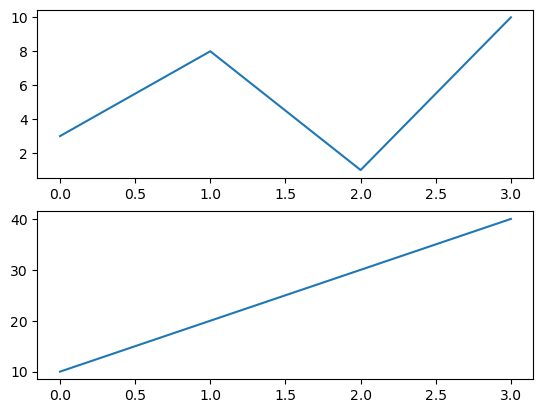

<Figure size 640x480 with 0 Axes>

In [2]:
# The subplot() function takes three arguments that describes the layout of the figure.
# The layout is organized in rows and columns, which are represented by the first and second argument.
# The third argument represents the index of the current plot( starts with 1 from upper left)

import matplotlib.pyplot as plt
import numpy as np

#plot 1:
x = np.array([0, 1, 2, 3])
y = np.array([3, 8, 1, 10])

plt.subplot(2, 1, 1)
plt.plot(x,y)

#plot 2:
x = np.array([0, 1, 2, 3])
y = np.array([10, 20, 30, 40])

plt.subplot(2, 1, 2)
plt.plot(x,y)

plt.show()
plt.tight_layout()                        # tight_layout()

### Subplot, Axis with secondary Axis

In [1]:
df = yf.download(tickers = ['BA','IBM'],period = '5y', progress= False)['Close']
fig, ax1 = plt.subplots(figsize =(16,6))                                                    # subplots()

ax2 = ax1.twinx()                                                                           # twinx()
ax1.plot(df_zValues.index, df_zValues['BA'], color = 'g',label = '# of Trades')             # ax.plot()
ax2.plot(df_zValues.index, df_zValues['IBM'], color = 'b',label = 'Strategy_PL')
ax1.set_xlabel('dates')                                                                     # set_xlabel()
ax1.set_ylabel('BA Price', color = 'g')                                                     # set_ylabel()
ax1.legend(loc='upper right')                                                               # legend()
ax2.set_ylabel('IBM price', color = 'b')
ax2.legend(loc='upper left')

NameError: name 'yf' is not defined

### Closed form of Covariance matrix

In [ ]:
np.random.seed(42)
X = np.random.normal(size =(100,4))
X[:,2] = 3 * X[:,0] - 2 * X[:,1] + np.random.normal(0, 0.1, 100)
X[:,3] = 1.5 * X[:,0] - 0.5 * X[:,1] + np.random.normal(0, 0.1, 100)

# de-mean each column(feature)
X = X - np.mean(X, axis = 0)

# closed form of covariance matrix
a =  np.array([X[i].reshape(-1,1)@X[i].reshape(1,-1) for i in range(100)])
cov_matrix = np.sum(a, axis = 0)

### Eigenvalue and Eigenvectors

In [ ]:
a = np.array([[1,2,3],[5,6,7],[9,10,11]])
np.linalg.eig(a)                            # linalg.eig() - eigenvalues and eigenvectors

### broadcasting

In [ ]:
# When operating on two arrays, NumPy compares their shapes element-wise.Two dimensions are compatible when they are equal
# OR
# one of them is 1
# refer to https://numpy.org/doc/stable/user/basics.broadcasting.html


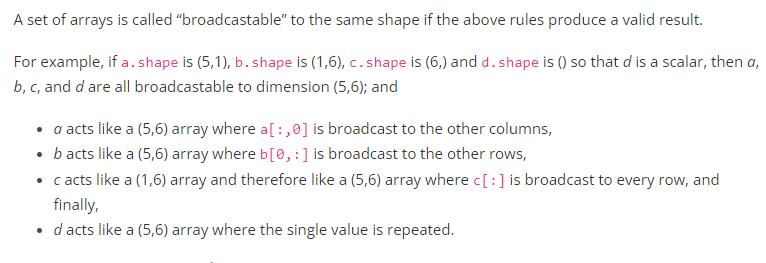

In [4]:
Image.open(r"C:\Admin\C Drive\Python Panda\Image.PNG")

### np.meshgrid & multidimesional Array

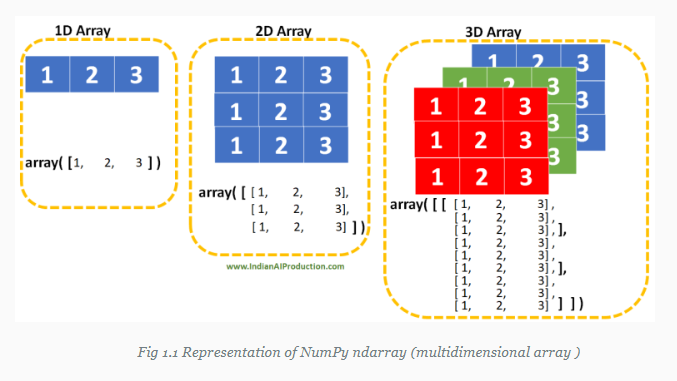

In [5]:
Image.open(r"C:\Admin\C Drive\Python Statistical Analysis\ndArray.PNG")

# s[0] for 3-d array means 2d array of Y-Z and so on... 

In [ ]:
# very useful to create meshgrid

na, nb = (5,3)
a = np.linspace(1,2,na)
b = np.linspace(1,2,nb)
#xa, xb = np.meshgrid(a,b, indexing= "ij")                        # np.meshgrid() - matrix coordinates
xa, xb = np.meshgrid(a,b, indexing= "xy", sparse=True)            # np.meshgrid() - cartesian coordinates
xa,xb
                  


a = np.arange(-10,10,0.1)
b = np.arange(-10,10,0.1)
x, y= np.meshgrid(a,b, indexing ="xy")
z = np.sin(x**2+y**2)/(x**2 +y**2)
plt.figure(figsize=(12,8))
plt.contourf(x,y,z)                                               # plt.contourf()/plt.contour()
plt.show()

points = np.dstack([x.flatten(), y.flatten()])                    # np.dstack() - stack one on top of other

### merging, joining and concatnating dataframes, and functools package

In [ ]:
# merge will give all columns from both the datafames with one cavaet- if joining key name is same they it is taken only once

path1 = 'C:\Users\Admin\Python Pandas Course\Course_Materials_Part2\Video_Lecture_NBs\men2004.csv'
path2 = 'C:\Users\Admin\Python Pandas Course\Course_Materials_Part2\Video_Lecture_NBs\men2008.csv'
path3 = 'C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\topfive_2004.csv'
path4 = 'C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\topfive_2008.csv'
path5 = 'C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\men2004_det.csv'
path6 = 'C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\men2008_det.csv'

men_2004 = pd.read_csv(path1)
men_2008 = pd.read_csv(path2)
top_five_2004 = pd.read_csv(path3)
top_five_2008 = pd.read_csv(path4)
men_2004_det = pd.read_csv(path5)
men_2008_det = pd.read_csv(path6)

#--------------------------------------------------------------------------------------------------------------
# concatenation -pd.concat()- along axis = 0,increase rows, axis = 1 means increase columns
pd.concat([men_2004,men_2008],axis=0,ignore_index=True,keys=None)                   # without outer key and with reset index

men_0408 = pd.concat([men_2004,men_2008],axis=0,ignore_index=False,keys=[2004,2008], names =['Year'])   # with outer key      
men_0408.reset_index(drop= False, inplace=True)
men_0408.drop(axis =1, labels =['level_1'], inplace=True)

#--------------------------------------------------------------------------------------------------------------
top_five_2008.rename(columns ={'bronze':'Bronze'},inplace=True)
top_five_2004.add(top_five_2008, fill_value= 0)                     # add() - this will add values on all possible combinations of index and columns
top_five_2004.sub(top_five_2008, fill_value= 0)                     # sub() - subtracts


#--------------------------------------------------------------------------------------------------------------
# joins
outer_join = men_2004.merge(men_2008, how = 'outer',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)  
                 
outer_join_wo_intersection = men_2004.merge(men_2008, how = 'outer',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)
outer_join_wo_intersection = outer_join_wo_intersection.loc[outer_join_wo_intersection._merge != 'both',:]

inner_join = men_2004.merge(men_2008,how= 'inner',on = 'Athlete',suffixes=('_2004','_2008'))

left_join = men_2004.merge(men_2008, how = 'left',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)

left_join_wo_intersection = men_2004.merge(men_2008, how = 'left',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)
left_join_wo_intersection = left_join_wo_intersection.loc[left_join_wo_intersection._merge != 'both',:]

right_join = men_2004.merge(men_2008, how = 'right',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)

# with differetnt column names

men_0408 = men_2004.merge(men_2008, how = 'outer',left_on='Athlete', right_on='Name',suffixes=('_2004','_2008'),indicator=True)
men_0408.Athlete.fillna(value = men_0408.Name, inplace =True)
men_0408.drop(axis =1,labels = ['Name','_merge'],inplace =True)


# joining key - column of one table and index of another table

men_0408 = men_2004.merge(men_2008, how = 'outer',left_on='Athlete', right_index=True,suffixes=('_2004','_2008'),indicator=True,)
men_0408.reset_index(inplace=True)
men_0408.drop(axis =1, labels = ['index'], inplace=True)

# joining on more than one column

men_0408_det = men_2004_det.merge(men_2008_det, how = 'outer',on = ['Athlete','Medal'], suffixes=('_2004','_2008'),indicator=True)

# same as merge() with no diff

pd.merge(men_2004,men_2008, how = 'outer',on = 'Athlete',suffixes=('_2004','_2008'), indicator=True)    # pd.merge()


# merging multiple dataframe using functools library and reduce() function
import functools as ft
list_df_all = [df_IRDelta,df_INFDelta,df_EQDelta,df_FXDelta,df_CMDelta]
df_merge = ft.reduce(lambda left, right : pd.merge(left, right, how = "outer",on= "Trade Id"),list_df_all)


### groupby operation 

In [ ]:
# basically, in a dataframe we groupby columns X, Y, Z based on columns a,b and c with specific function

# groupby will create combination of dfs, we need to cast it using list - this will create list of tuples,
# for tuple, 1st element is groupby key and second element is dataframe

# after groupby(lets say on keys A (4 values) & B (5 values), apply function on single col or multiple columns. 
# if single col then it will create series ,otherwise df of 4X5 rows.

summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\summer.csv')
split_1 = summer.groupby(['Country','Gender'])               # groupby() - panda groupby object - a combination of dataframes
list(split1)                                                 # casting groupby object 
list(split1)[0][1]                                           # list of tuples -first element is split key and second element is tuple

# this is panda series with multiindex = ['City','Medal']
a = summer.groupby(by = ['City','Medal']).Medal.count()
a.loc[('City','Medal')]                                      # similar to multindex 


# this is panda dataframe with multiindex = ['City','Medal']
b = summer.groupby(by = ['City','Medal']).count()
b.loc[('City','Medal'),:)].count()                           # similar to multindex

#--------------------------------------------------------------------------------------------------------------
# split-apply-combine
titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv')
titanic.groupby('sex')['fare','age'].max()                   # operations on selected columns
titanic.groupby('sex').max()                                 # operations on all columns

new_df = titanic.groupby('sex').mean()
plt.style.use = 'seaborn'
new_df.plot(kind = 'bar', subplots = True, figsize =(12,8))
plt.show()

medal_per_country = titanic.groupby('Country').Medal.count()
df1 = medal_per_country.nlargest(n=20)
plt.style.use = 'seaborn'
df1.plot(kind = 'bar', subplots = True, figsize =(12,8))      # bar charts are useful when index is categorical, # of stacks based on # of columns 
plt.show()

#--------------------------------------------------------------------------------------------------------------
# agg(), transform(), stack(), unstack()
titanic = pd.read_csv('C:\\Users\\Admin\\Python Pandas course\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv' )
titanic = titanic.loc[:,['survived','pclass','sex','age','fare']]
titanic.groupby('sex').agg({'survived':['mean','sum'],'pclass':['max'],'fare':['sum','mean'],'age':['max']})   # agg()

titanic.groupby('sex').agg(survival_rate = ('survived','mean'),survival_toal = ('survived','sum'),mean_age =('age','mean'))

titanic['avg_survival_rate'] = titanic.groupby(['sex','pclass']).survived.transform('mean')     # transform()

titanic['group_mean_age'] = titanic.groupby(['sex','pclass']).age.transform('mean')
titanic.age.fillna(titanic.group_mean_age,inplace =True)                                        # replacing na values with group specific value

summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\summer.csv')
medal_by_country = summer.groupby(['Country','Medal']).Medal.count()
a = medal_by_country.unstack(level =-1, fill_value=0)                          # unstack() with inner index, level = -1
b = medal_by_country.unstack(level =-2, fill_value=0)                          # unstack() with outer index, level = -2
c = a.stack()                                                                  # stack() - cols to rows

#------------------------------------------------------------------------------------------------------------------
# after combining string values across rows in groupby - take unique values and again join
new_df = pd.DataFrame(columns = ['first','second', 'city'])
new_df.loc[0,:] = ['prasoon','gupta','mumbai']
new_df.loc[1,:] = ['komal','gupta','mumbai']
new_df.loc[2,:] = ['parth','gupta','mumbai']
new_df.loc[3,:] = ['prasoon','gupta','delhi,mumbai']

new_df.groupby(['first','second']).agg({'city':','.join})                      # concatnating string column in groupby
new_df.groupby(['first','second']).city.transform(lambda x:','.join(x))

new_df['city'] = new_df.city.str.split(',').map(set).str.join(',')
new_df['city'] = new_df.city.str.replace(',','',n=1)

#--------------------------------------------------------------------------------------------------------------
# split-apply-combine with apply()
titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv', 
                      usecols=['survived','pclass','sex','age','fare'])

def group_mean(group):
    return group.mean()

def group_func(group):
    return group.loc[group.survived ==1,:].nlargest(5,'age')

titanic.groupby('sex').apply(group_mean)                       # since groupby object is combination of dataframes so apply func to every df

titanic.groupby('sex').apply(group_func)    



### reshaping and pivoting dataframe - pivot(), pivot_table(), unpivoting- pd.melt()

In [ ]:
# pivot is only for reshaping and no duplicate entries and no groupby

table1 = pd.read_csv('C:\\Users\\pgupt145\\Python Pandas course\\Course_Materials_Part2\\Video_Lecture_NBs\\table1.csv')
table2 =  pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\table2.csv')

table1_piv = table1.pivot(index = 'Country',columns='Medal',values='Count').fillna(0)      
table2.groupby(['Country','Year','Medal']).Count.sum().unstack().fillna(0).reset_index()  # pivot table with aggregation 

# pivot_table is similar to excel pivot table with groupby
# in pivot_table all rows with NA value(single or many) will be dropped, remember '-' is not null/nan/na/blank  
# values has to be numeric column - count wont work, for count cases use crosstab
# margin and margin_name is subtotal across rows and columns with name
table2.pivot_table(index=['Country','Year'],columns='Medal', values='Count',aggfunc = 'sum' ,fill_value=0, margins=True, 
                   margins_name='Sum')

# pd.crosstab() - similar results to above pivot_table()
# simple way to cross tabulate two columns - count of records for each combination
pd.crosstab(table1.Country, table1.Medal).fillna(0)

# unpivoting - pd.melt()

table_2012 = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\table_2012.csv')

table_2012_melted = pd.melt(table_2012,id_vars='Country',value_vars=['Gold','Silver','Bronze'],var_name='Medal',
                            value_name='Count')
tabl_2012_piv = table_2012_melted.pivot(index = 'Country',columns='Medal',values='Count')


### data prepration - arithmatic ops,map(), sample(),conditional transformation, discretization,outier handling, dummy variable

In [ ]:
titanic = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\titanic.csv')
sales = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\sales.csv', index_col=0)

#--------------------------------------------------------------------------------------------------------------
# arithmatic operations
# here, we can also apply simple operations but with below methods, we get additional attributes
sales_new = sales/sales.iloc[0]                                                       # operation on whole dataframe
sales['new_col_add'] = sales.Mon.add(sales.Thu, fill_value =0)                        # add()
sales['new_col_sub'] = sales.Mon.sub(sales.Thu, fill_value =0)                        # sub()
sales['per_bonus'] = [0.12,0.34,0.14,0.11]                    
sales['new_col_mul'] = sales.new_col_add.mul(sales.per_bonus, fill_value =0)          # mul()
sales['new_col_div'] = sales.new_col_add.div(sales.per_bonus, fill_value =0)          # div()

titanic['YoB'] = titanic.age.sub(1912, fill_value = 0).mul(-1)         
fx_eur = 1.1

#--------------------------------------------------------------------------------------------------------------
# map(), sample()
summer = pd.read_csv('C:\\Users\\pgupt145\\Panda course\\Course_Materials_Part2\\Video_Lecture_NBs\\summer.csv ')
city_map = {'London':'UK','Montreal':'Canada','Barcelona':'Spain','Mexico':'Mexico','Moscow':'Russia','Paris':'France','Athens':'Greece'}


sample = summer.sample(n= 10, random_state =123)                      # sample() - random rows sample from df
summer['host_country'] = sample.City.map(city_map)                    # map()

# conditional transformation

titanic['alone'] = pd.Series(np.where(titanic.sibsp ==0,'Yes','No'))                             # np.where()

# discretization, here dtype - category
# right = False means excluding right value in bin
age_bins = [0,10,20,30,40,50,60,70,80]
age_category = ['age1','age2','age3','age4','age5','age6','age7','age8']
titanic['age_bin'] = pd.cut(titanic.age,bins=age_bins,labels=age_category,right = False)         # pd.cut() - discretization


titanic['fare_cut']=pd.cut(titanic.fare,bins =5,precision=0)                                     # pd.cut() - discretization
titanic['fare_cut_quantile']=pd.qcut(titanic.fare,q =5)                                          # pd.qcut() - quantile based   
titanic['fare_cut_quantile']=pd.qcut(titanic.fare,q =[0,0.1,0.25,0.5,0.9,1])

# outliers handling

cap_fare = 250
titanic.loc[titanic.fare > cap_fare, 'fare'] = cap_fare
floor_fare = 5
titanic.loc[titanic.fare < floor_fare, 'fare'] = floor_fare

# creating dummy variables - converting categorical variables to dummy variables
# categorical(numeric/nonnumeric), continuous/discrete(numeric)

titanic_mod = pd.get_dummies(data = titanic,columns = ['sex','pclass'])             # pd.get_dummies()
